In [6]:
!pip install ucimlrepo shap scikit-learn xgboost openpyxl -q

In [7]:
import pandas as pd
xl = pd.ExcelFile("extention of Z-Alizadeh sani dataset.xlsx")
print(xl.sheet_names)
df = pd.read_excel(xl, sheet_name=0)
print(df.shape)
print(list(df.columns))
print(df.tail(3).T)

FileNotFoundError: [Errno 2] No such file or directory: 'extention of Z-Alizadeh sani dataset.xlsx'

In [8]:
import os
print(os.getcwd())
print(os.listdir())


C:\Users\hi\Desktop\internship
['.ipynb_checkpoints', 'Biotech.ipynb', 'Goal', 'internship.ipynb', 'Leads_cleaned', 'ML Lead score project', 'Python-for-Data-Analysis.pdf', 'road map.pdf']


In [9]:
import glob, os
p = glob.glob(os.path.expanduser("~/Downloads/*lizadeh*"))
print(p)

['C:\\Users\\hi/Downloads\\extention+of+z+alizadeh+sani+dataset.zip']


In [11]:
import zipfile, os, pandas as pd

zpath = p[0]
out = os.path.expanduser("~/Downloads/zali")
with zipfile.ZipFile(zpath) as z:
    print(z.namelist())
    z.extractall(out)

# find the data file inside
files = [os.path.join(r, f) for r, _, fs in os.walk(out) for f in fs
         if f.lower().endswith((".xlsx", ".xls", ".csv"))]
print(files)

f = files[0]
df = pd.read_csv(f) if f.endswith(".csv") else pd.read_excel(f)
print(df.shape)
print(list(df.columns))

['extention of Z-Alizadeh sani dataset.xlsx']
['C:\\Users\\hi/Downloads/zali\\extention of Z-Alizadeh sani dataset.xlsx']
(303, 59)
['Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Typical Chest Pain', 'Dyspnea', 'Function Class', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'LVH', 'Poor R Progression', 'BBB', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA', 'VHD', 'LAD', 'LCX', 'RCA', 'Cath']


In [14]:
import numpy as np, pandas as pd, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

targets = ["Cath", "LAD", "LCX", "RCA"]

# look at the target values first
for t in targets:
    print(t, df[t].unique())

# inputs = everything except the 4 targets (prevents leakage)
X = df.drop(columns=targets)
X = pd.get_dummies(X, drop_first=True).astype(float)   # text columns -> numbers
feature_cols = list(X.columns)

# 1 = disease/stenosis, 0 = normal
neg = {"normal", "0", "0.0", "no", "n"}
def to01(s):
    return (~s.astype(str).str.strip().str.lower().isin(neg)).astype(int)

models, rows = {}, []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for t in targets:
    y = to01(df[t])
    m = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
    prob = cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append([t, y.mean().round(2), accuracy_score(y, pred), precision_score(y, pred),
                 recall_score(y, pred), f1_score(y, pred), roc_auc_score(y, prob)])
    models[t] = m.fit(X, y)

res = pd.DataFrame(rows, columns=["target", "positive_rate", "accuracy", "precision", "recall", "f1", "roc_auc"]).round(3)
print(res)

joblib.dump({"models": models, "features": feature_cols}, "heart_models.joblib")
X.to_csv("X_processed.csv", index=False)
res.to_csv("results.csv", index=False)
print("saved")

Cath <ArrowStringArray>
['CAD', 'Normal']
Length: 2, dtype: str
LAD <ArrowStringArray>
['Stenotic', 'Normal']
Length: 2, dtype: str
LCX <ArrowStringArray>
['Normal', 'Stenotic']
Length: 2, dtype: str
RCA <ArrowStringArray>
['Stenotic', 'Normal']
Length: 2, dtype: str
  target  positive_rate  accuracy  precision  recall     f1  roc_auc
0   Cath           0.71     0.865      0.896   0.917  0.906    0.921
1    LAD           0.58     0.795      0.804   0.859  0.831    0.851
2    LCX           0.39     0.673      0.582   0.597  0.589    0.722
3    RCA           0.38     0.650      0.538   0.491  0.514    0.712
saved


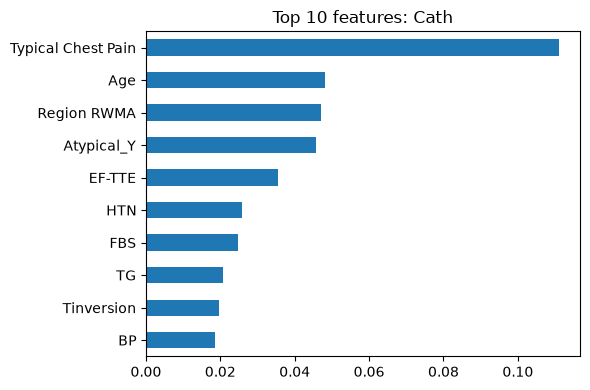

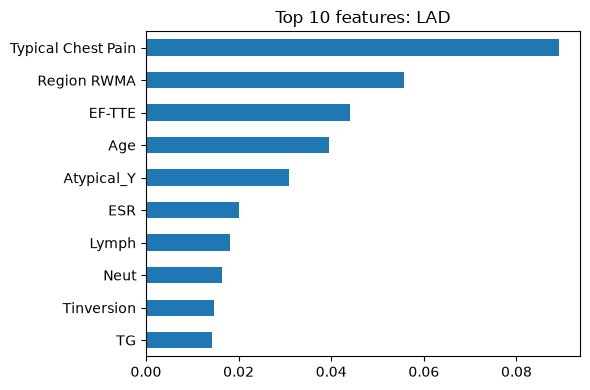

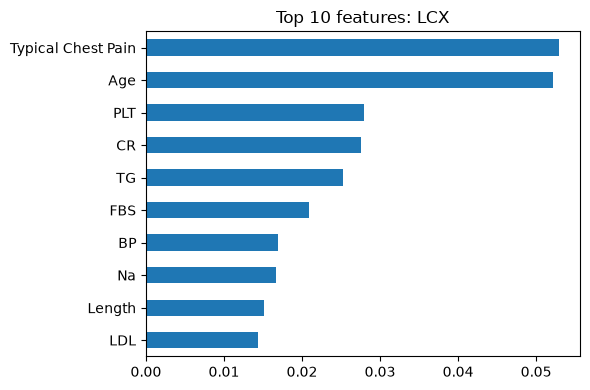

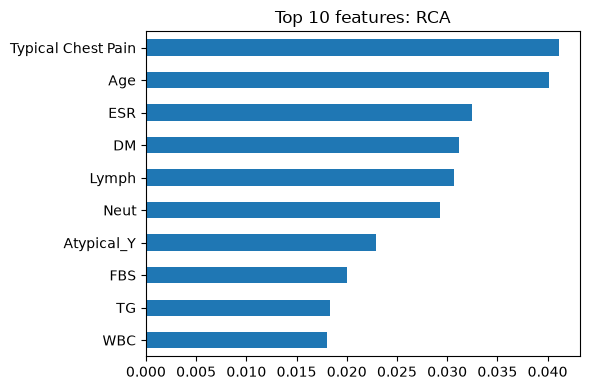

In [15]:
import shap, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt

bundle = joblib.load("heart_models.joblib")
models, feats = bundle["models"], bundle["features"]
X = pd.read_csv("X_processed.csv")

def pos_shap(model, data):
    sv = shap.TreeExplainer(model).shap_values(data)
    if isinstance(sv, list):
        return np.array(sv[1])
    sv = np.array(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

for t in ["Cath", "LAD", "LCX", "RCA"]:
    sv = pos_shap(models[t], X)
    imp = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values().tail(10)
    plt.figure(figsize=(6, 4))
    imp.plot(kind="barh")
    plt.title(f"Top 10 features: {t}")
    plt.tight_layout()
    plt.savefig(f"shap_{t}.png", dpi=150)
    plt.show()

In [16]:
import json, shap, joblib, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier

bundle = joblib.load("heart_models.joblib")
models, feats = bundle["models"], bundle["features"]
X = pd.read_csv("X_processed.csv")
targets = ["Cath", "LAD", "LCX", "RCA"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def pos_shap(model, data):
    sv = shap.TreeExplainer(model).shap_values(data)
    if isinstance(sv, list):
        return np.array(sv[1])
    sv = np.array(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

patients = [{"id": i + 1} for i in range(len(X))]
for t in targets:
    y = (df[t].astype(str).str.strip().str.lower() != "normal").astype(int)
    m = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
    prob = cross_val_predict(m, X, y, cv=cv, method="predict_proba")[:, 1]
    sv = pos_shap(models[t], X)
    for i in range(len(X)):
        idx = np.argsort(-np.abs(sv[i]))[:5]
        patients[i][t] = {
            "p": round(float(prob[i]), 3),
            "actual": int(y.iloc[i]),
            "top": [[feats[j], round(float(sv[i][j]), 3), round(float(X.iloc[i][feats[j]]), 2)] for j in idx],
        }

open("data.js", "w").write("const DATA = " + json.dumps(patients) + ";")
print("data.js saved,", len(patients), "patients")

data.js saved, 303 patients


In [17]:
html = r'''<!DOCTYPE html>
<html><head><meta charset="utf-8"><title>CardioViz 3D</title>
<style>
body{font-family:Arial,sans-serif;margin:0;background:#10151c;color:#e8eaed}
.warn{background:#b71c1c;color:#fff;padding:8px 14px;font-size:14px;text-align:center}
.wrap{display:flex;flex-wrap:wrap}
#view{flex:2;min-width:320px;height:560px}
#panel{flex:1;min-width:300px;padding:14px}
.bar{background:#2a313b;border-radius:4px;height:14px;margin:2px 0 8px}
.fill{height:14px;border-radius:4px}
.row{cursor:pointer;padding:4px 6px;border-radius:6px}
.row.sel{background:#243040}
select{font-size:16px;padding:4px}
small{color:#9aa4b2}
</style></head><body>
<div class="warn">Predictions are for decision support / educational purposes only and are NOT a substitute for formal diagnostic imaging or a doctor.</div>
<div class="wrap">
<div id="view"></div>
<div id="panel">
<h2 style="margin-top:0">CardioViz 3D</h2>
<label>Patient: <select id="pat"></select></label>
<p><small>Rotate: drag. Zoom: scroll. Click an artery (or a row) to see why.</small></p>
<div id="bars"></div>
<h3 id="exTitle"></h3>
<div id="ex"></div>
<p><small>Colors: green = low risk, yellow = medium, red = high stenosis probability (cross-validated Random Forest + SHAP).</small></p>
</div></div>
<script src="https://cdn.jsdelivr.net/npm/three@0.128.0/build/three.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/three@0.128.0/examples/js/controls/OrbitControls.js"></script>
<script src="data.js"></script>
<script>
const NAMES={Cath:"Overall CAD",LAD:"LAD",LCX:"LCX",RCA:"RCA"};
const view=document.getElementById("view");
const W=()=>view.clientWidth,H=()=>view.clientHeight;
const scene=new THREE.Scene();
const cam=new THREE.PerspectiveCamera(45,W()/H(),0.1,100);cam.position.set(0,0,6.5);
const renderer=new THREE.WebGLRenderer({antialias:true});
renderer.setSize(W(),H());renderer.setClearColor(0x10151c);view.appendChild(renderer.domElement);
scene.add(new THREE.AmbientLight(0xffffff,0.7));
const dl=new THREE.DirectionalLight(0xffffff,0.8);dl.position.set(3,4,6);scene.add(dl);
const controls=new THREE.OrbitControls(cam,renderer.domElement);

const pts=[];
for(let i=0;i<=100;i++){const t=i/100*2*Math.PI;
 pts.push(new THREE.Vector2(16*Math.pow(Math.sin(t),3)*0.1,(13*Math.cos(t)-5*Math.cos(2*t)-2*Math.cos(3*t)-Math.cos(4*t))*0.1));}
const geo=new THREE.ExtrudeGeometry(new THREE.Shape(pts),{depth:1,bevelEnabled:true,bevelThickness:0.2,bevelSize:0.15,bevelSegments:6,curveSegments:40});
geo.center();
const group=new THREE.Group();
group.add(new THREE.Mesh(geo,new THREE.MeshPhongMaterial({color:0x9c4a4a,transparent:true,opacity:0.92})));

const z=0.8;
const paths={
 LAD:[[0.2,0.8],[0.3,0.1],[0.25,-0.6],[0.1,-1.2]],
 LCX:[[0.2,0.8],[0.7,0.8],[1.0,0.4],[1.0,-0.2]],
 RCA:[[-0.2,0.8],[-0.7,0.8],[-1.0,0.4],[-1.0,-0.2],[-0.6,-0.8]]
};
const tubes={};
for(const k in paths){
 const curve=new THREE.CatmullRomCurve3(paths[k].map(p=>new THREE.Vector3(p[0],p[1],z)));
 const m=new THREE.Mesh(new THREE.TubeGeometry(curve,40,0.09,12,false),new THREE.MeshPhongMaterial({color:0x2ecc71}));
 m.userData.name=k;tubes[k]=m;group.add(m);
}
scene.add(group);

function col(p){
 const g=new THREE.Color(0x2ecc71),y=new THREE.Color(0xf1c40f),r=new THREE.Color(0xe53935);
 return p<0.5?g.lerp(y,p*2):y.lerp(r,(p-0.5)*2);
}
let sel="Cath";
const pat=document.getElementById("pat");
DATA.forEach((d,i)=>{const o=document.createElement("option");o.value=i;o.text="Patient "+d.id;pat.appendChild(o);});
pat.onchange=update;

function update(){
 const d=DATA[+pat.value];
 for(const k in tubes){tubes[k].material.color.copy(col(d[k].p));}
 let h="";
 for(const k of ["Cath","LAD","LCX","RCA"]){
  const p=d[k].p,c="#"+col(p).getHexString();
  h+=`<div class="row ${k===sel?"sel":""}" onclick="pick('${k}')"><b>${NAMES[k]}</b>: ${(p*100).toFixed(0)}% <small>(dataset says: ${d[k].actual?"disease":"normal"})</small><div class="bar"><div class="fill" style="width:${p*100}%;background:${c}"></div></div></div>`;
 }
 document.getElementById("bars").innerHTML=h;
 document.getElementById("exTitle").innerText="Why: "+NAMES[sel]+" prediction";
 document.getElementById("ex").innerHTML=d[sel].top.map(t=>`<div>${t[0]} = ${t[2]} <b style="color:${t[1]>0?"#ff6b6b":"#5dd39e"}">${t[1]>0?"raises":"lowers"} risk (${t[1]>0?"+":""}${t[1]})</b></div>`).join("");
}
window.pick=k=>{sel=k;update();};
update();

const ray=new THREE.Raycaster(),mouse=new THREE.Vector2();
renderer.domElement.addEventListener("click",e=>{
 const r=renderer.domElement.getBoundingClientRect();
 mouse.x=((e.clientX-r.left)/r.width)*2-1;mouse.y=-((e.clientY-r.top)/r.height)*2+1;
 ray.setFromCamera(mouse,cam);
 const hit=ray.intersectObjects(Object.values(tubes));
 if(hit.length){sel=hit[0].object.userData.name;update();}
});
window.addEventListener("resize",()=>{cam.aspect=W()/H();cam.updateProjectionMatrix();renderer.setSize(W(),H());});
(function loop(t){requestAnimationFrame(loop);const s=1+0.02*Math.sin(t/220);group.scale.set(s,s,s);controls.update();renderer.render(scene,cam);})(0);
</script></body></html>'''
open("index.html", "w", encoding="utf-8").write(html)
print("index.html saved")

index.html saved


In [18]:
import urllib.request
base = "https://cdn.jsdelivr.net/npm/three@0.128.0/"
urllib.request.urlretrieve(base + "build/three.min.js", "three.min.js")
urllib.request.urlretrieve(base + "examples/js/controls/OrbitControls.js", "OrbitControls.js")

h = open("index.html", encoding="utf-8").read()
h = h.replace(base + "build/three.min.js", "three.min.js")
h = h.replace(base + "examples/js/controls/OrbitControls.js", "OrbitControls.js")
open("index.html", "w", encoding="utf-8").write(h)
print("done")

done


In [19]:
import re, os, urllib.request

def get(name, urls):
    if os.path.exists(name) and os.path.getsize(name) > 5000:
        return open(name, encoding="utf-8").read()
    for u in urls:
        try:
            req = urllib.request.Request(u, headers={"User-Agent": "Mozilla/5.0"})
            txt = urllib.request.urlopen(req, timeout=30).read().decode("utf-8")
            if len(txt) > 5000:
                open(name, "w", encoding="utf-8").write(txt)
                return txt
        except Exception as e:
            print("failed:", u, e)
    raise SystemExit("Could not download " + name)

three = get("three.min.js", [
    "https://cdn.jsdelivr.net/npm/three@0.128.0/build/three.min.js",
    "https://unpkg.com/three@0.128.0/build/three.min.js"])
orbit = get("OrbitControls.js", [
    "https://cdn.jsdelivr.net/npm/three@0.128.0/examples/js/controls/OrbitControls.js",
    "https://unpkg.com/three@0.128.0/examples/js/controls/OrbitControls.js"])
data = open("data.js", encoding="utf-8").read()

h = open("index.html", encoding="utf-8").read()
tags = re.findall(r'<script src="[^"]*"></script>', h)
print("replacing:", tags)
h = h.replace(tags[0], "<script>" + three + "</script>")
h = h.replace(tags[1], "<script>" + orbit + "</script>")
h = h.replace(tags[2], "<script>" + data + "</script>")
open("index_standalone.html", "w", encoding="utf-8").write(h)
print("saved index_standalone.html", round(len(h)/1e6, 2), "MB")

replacing: ['<script src="three.min.js"></script>', '<script src="OrbitControls.js"></script>', '<script src="data.js"></script>']
saved index_standalone.html 0.85 MB


In [20]:
import pandas as pd
print(pd.read_csv("results.csv").to_string())

  target  positive_rate  accuracy  precision  recall     f1  roc_auc
0   Cath           0.71     0.865      0.896   0.917  0.906    0.921
1    LAD           0.58     0.795      0.804   0.859  0.831    0.851
2    LCX           0.39     0.673      0.582   0.597  0.589    0.722
3    RCA           0.38     0.650      0.538   0.491  0.514    0.712


In [21]:
NAME = "SparkCoders"

readme = f'''# CardioViz 3D - Cardiovascular Risk Visualization & Prediction
Multimodal AI Hackathon 2026, Track A (BioTech). Team: {NAME}

**Predictions are for decision support / educational purposes only and are NOT a substitute for formal diagnostic imaging or a doctor.**

## What it does
- Trains models on the UCI "Extension of Z-Alizadeh Sani" dataset (303 patients, 59 features) to predict overall CAD (`Cath`) and stenosis of the three coronary arteries: LAD, LCX and RCA.
- Shows an interactive 3D heart (Three.js) where the LAD, LCX and RCA arteries change color (green, yellow, red) with the predicted stenosis probability.
- Clinical dashboard: per-patient probabilities, the dataset's actual label, and the top 5 SHAP features showing why the model predicted that risk. You can rotate, zoom, and click an artery to see its explanation.

## Method
1. Inputs: the 55 demographic, symptom/exam, ECG, lab and echo features. `LAD`, `LCX`, `RCA` and `Cath` are removed from the inputs to prevent target leakage.
2. Text columns are one-hot encoded. Labels: Normal = 0, CAD/Stenotic = 1.
3. One Random Forest (300 trees, balanced class weights) per target.
4. Evaluation: 5-fold stratified cross-validation (out-of-fold predictions).
5. Explanations: SHAP TreeExplainer. The patient probabilities shown in the 3D page are the cross-validated (out-of-fold) predictions.

## Results (5-fold cross-validation)
| Target | Positive rate | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|---|
| Overall CAD (Cath) | 0.71 | 0.865 | 0.896 | 0.917 | 0.906 | 0.921 |
| LAD | 0.58 | 0.795 | 0.804 | 0.859 | 0.831 | 0.851 |
| LCX | 0.39 | 0.673 | 0.582 | 0.597 | 0.589 | 0.722 |
| RCA | 0.38 | 0.650 | 0.538 | 0.491 | 0.514 | 0.712 |

Overall CAD and LAD are predicted well. LCX and RCA are harder: the dataset has only 303 patients and no direct imaging data, so these two models are weaker. This is a limitation, not a clinical tool.

## Files
- `Biotech.ipynb` - data loading, training, evaluation, SHAP and export code
- `index_standalone.html` - the 3D web app (open directly in a browser, no server needed)
- `index.html`, `data.js` - non-standalone version of the same app
- `results.csv` - evaluation metrics
- `shap_Cath.png`, `shap_LAD.png`, `shap_LCX.png`, `shap_RCA.png` - feature importance charts
- `heart_models.joblib`, `X_processed.csv` - trained models and processed inputs

## Prerequisites
Python 3.10+, JupyterLab, and these packages: pandas, numpy, scikit-learn, shap, matplotlib, joblib, openpyxl.

## Setup and run
1. Install the packages:

        pip install pandas numpy scikit-learn shap matplotlib joblib openpyxl

2. Download the dataset from https://archive.ics.uci.edu/dataset/411 (extension of Z-Alizadeh Sani, CC BY 4.0), unzip it, and put the .xlsx file next to the notebook.
3. Open `Biotech.ipynb` in JupyterLab and run all cells. This trains the models, saves the SHAP charts, and writes `data.js`.
4. To view the app, double-click `index_standalone.html` (or `index.html`) to open it in Chrome or Edge. Pick a patient, rotate and zoom the heart, and click an artery to see its explanation.

## Dataset credit
Alizadehsani, R., Roshanzamir, M., Sani, Z. (2013). Extension of Z-Alizadeh Sani dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5461K
'''
open("README.md", "w", encoding="utf-8").write(readme)
print("README.md saved")

README.md saved
